In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# The notebook runs from the "notebooks" folder, so the project root is one level up.
# Adding it to sys.path lets us import our own code from src/, exactly like the pipeline does.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_ROOT))

# Reuse the column names and sensor descriptions from config.py,
# so the notebook and the pipeline always agree.
from src.config import SENSOR_COLUMNS, SETTING_COLUMNS, SENSOR_DESCRIPTIONS

DATA_DIR = PROJECT_ROOT / "data" / "interim"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Load the FD001 training data written by the ingest stage
train = pd.read_parquet(DATA_DIR / "train_FD001.parquet")

print("Project root:", PROJECT_ROOT)
print("Rows, columns:", train.shape)
train.head()

Project root: /aiops-storage/AIOps/turbofan-pdm
Rows, columns: (20631, 29)


,unit,cycle,setting_1,setting_2,setting_3,s1,s2,s3,s4,s5,...,s15,s16,s17,s18,s19,s20,s21,rul,label,subset
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8.4195,0.03,392,2388,100.0,39.06,23.4190,191,0,FD001
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8.4318,0.03,392,2388,100.0,39.00,23.4236,190,0,FD001
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8.4178,0.03,390,2388,100.0,38.95,23.3442,189,0,FD001
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8.3682,0.03,392,2388,100.0,38.88,23.3739,188,0,FD001
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8.4294,0.03,393,2388,100.0,38.90,23.4044,187,0,FD001


count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64


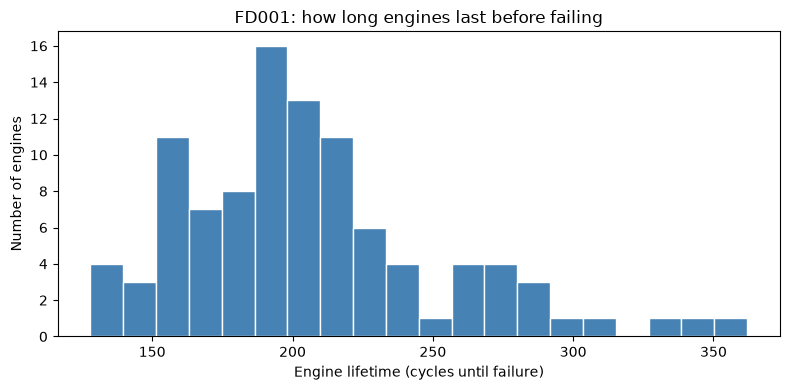

In [2]:
# For each engine, the last cycle is the cycle at which it failed
lifetimes = train.groupby("unit")["cycle"].max()
print(lifetimes.describe().round(1))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(lifetimes, bins=20, color="steelblue", edgecolor="white")
ax.set_xlabel("Engine lifetime (cycles until failure)")
ax.set_ylabel("Number of engines")
ax.set_title("FD001: how long engines last before failing")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_engine_lifetimes.png", dpi=120)
plt.show()

In [3]:
# Standard deviation of each column: how much it varies across all rows
spread = train[SENSOR_COLUMNS + SETTING_COLUMNS].std().sort_values()
print(spread.round(5))

# Anything below this tiny threshold is effectively constant
flat_columns = spread[spread < 1e-4].index.tolist()
print("\nFlat columns (no information):", flat_columns)

s1            0.00000
s10           0.00000
s19           0.00000
s18           0.00000
setting_3     0.00000
s16           0.00000
s5            0.00000
setting_2     0.00029
s6            0.00139
setting_1     0.00219
s15           0.03751
s8            0.07099
s13           0.07192
s21           0.10825
s20           0.18075
s11           0.26709
s2            0.50005
s12           0.73755
s7            0.88509
s17           1.54876
s3            6.13115
s4            9.00060
s14          19.07618
s9           22.08288
dtype: float64

Flat columns (no information): ['s1', 's10', 's19', 's18', 'setting_3', 's16', 's5']


s11   -0.696
s4    -0.679
s15   -0.643
s2    -0.606
s17   -0.606
s3    -0.585
s8    -0.564
s13   -0.563
s9    -0.390
s14   -0.307
s6    -0.128
s20    0.629
s21    0.636
s7     0.657
s12    0.672
Name: rul, dtype: float64


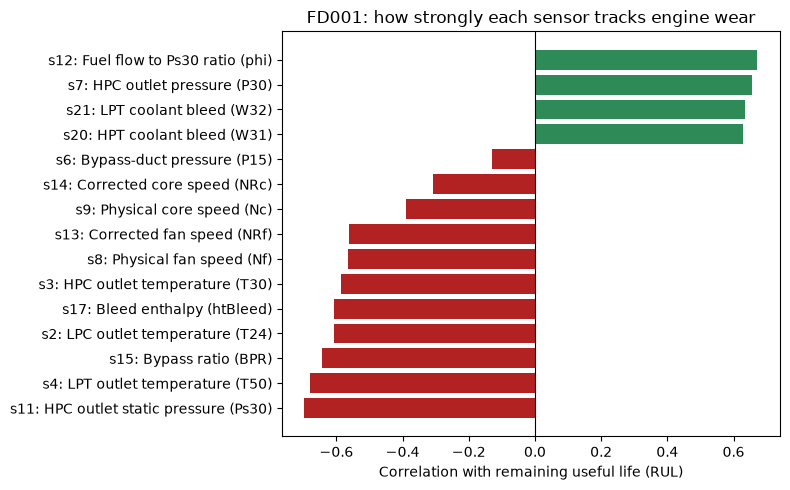

In [4]:
# Sensors that actually vary
useful_sensors = [s for s in SENSOR_COLUMNS if s not in flat_columns]

# Correlation of each sensor with remaining useful life
corr_with_rul = train[useful_sensors + ["rul"]].corr()["rul"].drop("rul").sort_values()
print(corr_with_rul.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
# Red = sensor rises as the engine wears out, green = sensor falls
colors = ["firebrick" if v < 0 else "seagreen" for v in corr_with_rul]
labels = [f"{s}: {SENSOR_DESCRIPTIONS[s]}" for s in corr_with_rul.index]
ax.barh(labels, corr_with_rul.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlation with remaining useful life (RUL)")
ax.set_title("FD001: how strongly each sensor tracks engine wear")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_sensor_rul_correlation.png", dpi=120)
plt.show()

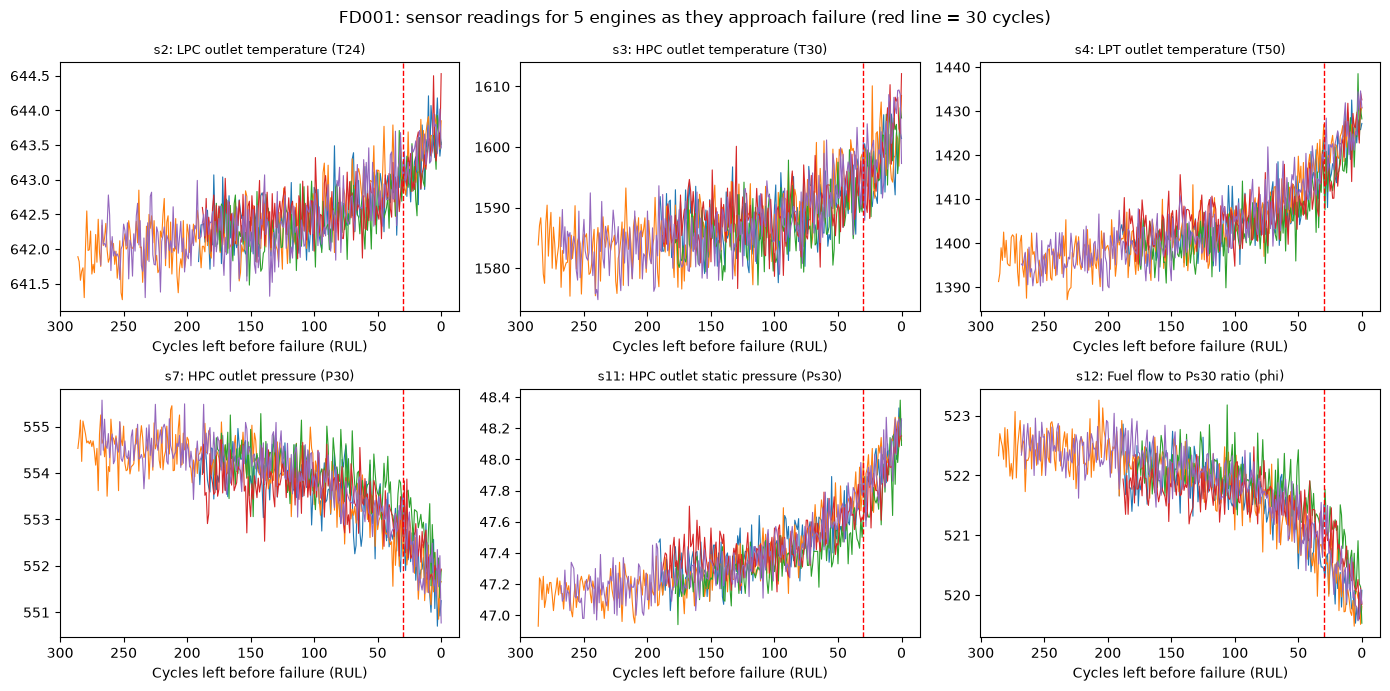

In [5]:
# Six of the sensors most strongly linked to wear
sensors_to_plot = ["s2", "s3", "s4", "s7", "s11", "s12"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, sensor in zip(axes.flat, sensors_to_plot):
    # One line per engine, for engines 1 to 5
    for unit in [1, 2, 3, 4, 5]:
        engine = train[train["unit"] == unit]
        ax.plot(engine["rul"], engine[sensor], linewidth=0.8)
    ax.invert_xaxis()  # so time runs left to right, ending at failure
    ax.axvline(30, color="red", linestyle="--", linewidth=1)  # our 30-cycle warning line
    ax.set_title(f"{sensor}: {SENSOR_DESCRIPTIONS[sensor]}", fontsize=9)
    ax.set_xlabel("Cycles left before failure (RUL)")

fig.suptitle("FD001: sensor readings for 5 engines as they approach failure (red line = 30 cycles)")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_degradation_trends.png", dpi=120)
plt.show()

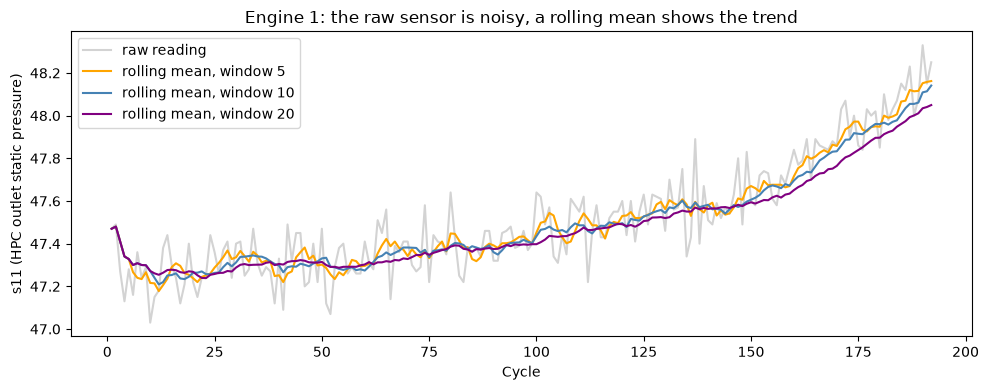

Noise ratio (higher = noisier, above 1 = mostly noise):
s14    0.23
s9     0.27
s11    0.54
s12    0.58
s8     0.60
s13    0.60
s4     0.63
s7     0.65
s15    0.76
s20    0.79
s21    0.79
s2     0.85
s17    0.86
s3     0.92
s6     1.36
dtype: float64


In [6]:
# --- Part A: raw readings vs rolling means, for one sensor of engine 1 ---
engine_1 = train[train["unit"] == 1].set_index("cycle")["s11"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(engine_1, color="lightgray", label="raw reading")
for window, color in [(5, "orange"), (10, "steelblue"), (20, "purple")]:
    # mean of the last `window` cycles; min_periods=1 lets early cycles use what exists
    ax.plot(engine_1.rolling(window, min_periods=1).mean(), color=color,
            label=f"rolling mean, window {window}")
ax.set_xlabel("Cycle")
ax.set_ylabel("s11 (HPC outlet static pressure)")
ax.set_title("Engine 1: the raw sensor is noisy, a rolling mean shows the trend")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "04_rolling_window.png", dpi=120)
plt.show()

# --- Part B: how noisy is each sensor compared with its real variation? ---
# diff() = change from one cycle to the next, computed within each engine
cycle_to_cycle_noise = train.groupby("unit")[useful_sensors].diff().std()
overall_spread = train[useful_sensors].std()
noise_ratio = (cycle_to_cycle_noise / overall_spread).round(2).sort_values()
print("Noise ratio (higher = noisier, above 1 = mostly noise):")
print(noise_ratio)

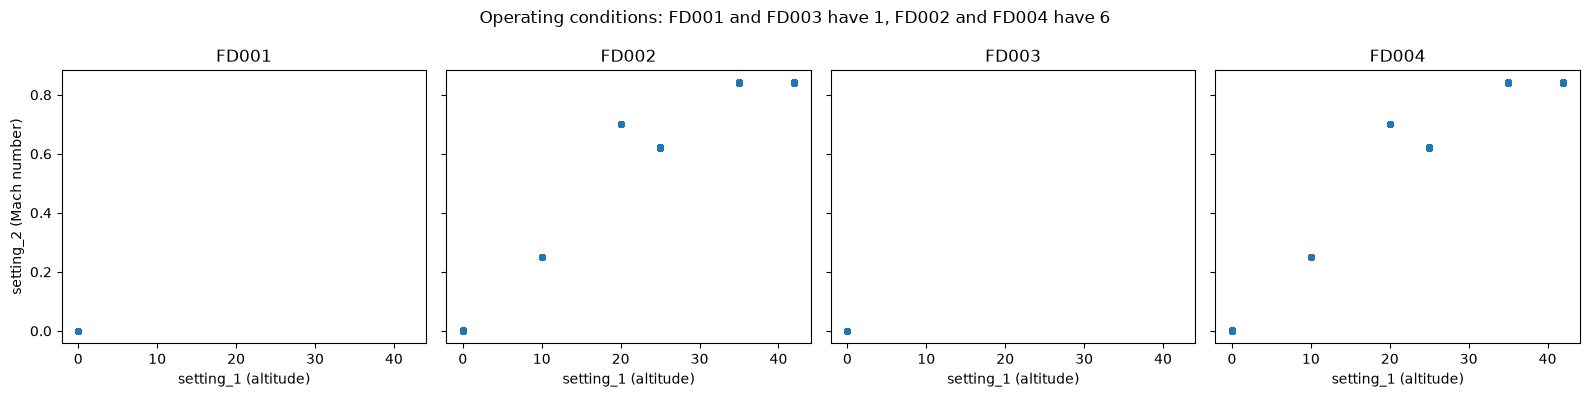

FD001:  20631 rows, 1 distinct operating condition(s)
FD002:  53759 rows, 6 distinct operating condition(s)
FD003:  24720 rows, 1 distinct operating condition(s)
FD004:  61249 rows, 6 distinct operating condition(s)


In [7]:
# Load the training data of all four subsets
subsets = {
    name: pd.read_parquet(DATA_DIR / f"train_{name}.parquet")
    for name in ["FD001", "FD002", "FD003", "FD004"]
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)
for ax, (name, df) in zip(axes, subsets.items()):
    sample = df.sample(3000, random_state=0)  # a sample is enough to see the pattern
    ax.scatter(sample["setting_1"], sample["setting_2"], s=15, alpha=0.4)
    ax.set_title(name)
    ax.set_xlabel("setting_1 (altitude)")
axes[0].set_ylabel("setting_2 (Mach number)")
fig.suptitle("Operating conditions: FD001 and FD003 have 1, FD002 and FD004 have 6")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_operating_conditions.png", dpi=120)
plt.show()

# Count distinct operating conditions (rounding removes tiny measurement noise)
for name, df in subsets.items():
    n_conditions = df[SETTING_COLUMNS].round(0).drop_duplicates().shape[0]
    print(f"{name}: {len(df):>6} rows, {n_conditions} distinct operating condition(s)")

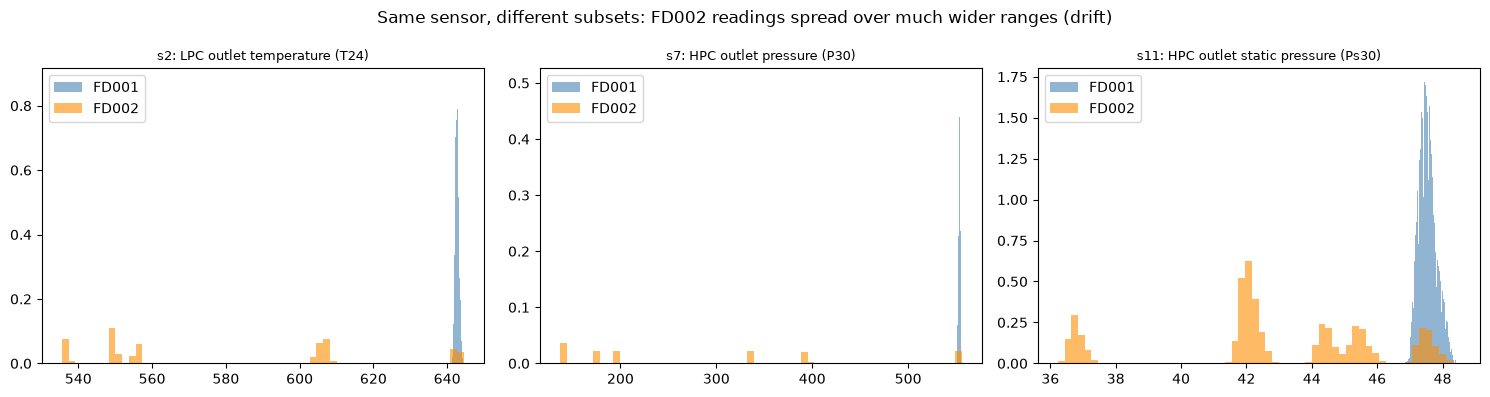

s2: FD001 range 641.2 to 644.5 | FD002 range 535.5 to 644.5
s7: FD001 range 549.9 to 556.1 | FD002 range 136.8 to 555.8
s11: FD001 range 46.9 to 48.5 | FD002 range 36.2 to 48.5


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, sensor in zip(axes, ["s2", "s7", "s11"]):
    for name, color in [("FD001", "steelblue"), ("FD002", "darkorange")]:
        # density=True scales each histogram so subsets of different sizes are comparable
        ax.hist(subsets[name][sensor], bins=60, alpha=0.6, density=True,
                color=color, label=name)
    ax.set_title(f"{sensor}: {SENSOR_DESCRIPTIONS[sensor]}", fontsize=9)
    ax.legend()
fig.suptitle("Same sensor, different subsets: FD002 readings spread over much wider ranges (drift)")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_drift_fd001_vs_fd002.png", dpi=120)
plt.show()

for sensor in ["s2", "s7", "s11"]:
    a, b = subsets["FD001"][sensor], subsets["FD002"][sensor]
    print(f"{sensor}: FD001 range {a.min():.1f} to {a.max():.1f} | "
          f"FD002 range {b.min():.1f} to {b.max():.1f}")